# Live-Coupled SWAN + GA Array Optimization — California Bay

---

## Overview

This notebook implements a **fully coupled** SWAN + Genetic Algorithm workflow for optimizing WEC array layouts using **physically resolved wave fields**. Unlike the standalone GA notebook (which assumes a uniform wave field), here the SWAN model provides a spatially varying 2-D wave field that accounts for bathymetric refraction, shoaling, and all nearshore transformation processes.

### Workflow

```
1. Read best site from AHP-TOPSIS (best_site.json)
2. Inject BLOCK output into SWAN input for the deployment area
3. Execute SWAN  -->  resolved Hs, Tp, Dir over 2-D grid
4. Read SWAN .MAT block output  -->  time-averaged wave field
5. Build a wave power interpolator from SWAN output
6. GA fitness: interpolate SWAN wave field to WEC positions,
   apply q-factor corrections for array interactions
7. Return optimal layout
```

### Why Couple with SWAN?

In nearshore waters, the wave field is **not uniform**:
- Waves refract around headlands, creating focusing/defocusing zones
- Shoaling amplifies wave height in shallow water
- Depth-induced breaking limits wave height near shore
- Wind-wave interactions add local energy

By using the SWAN-resolved field, each WEC in the array "sees" the correct local wave conditions, leading to more realistic power estimates and better-informed array layouts.

### Prerequisites

- **SWAN must be installed** and available on PATH
- `best_site.json` from the AHP-TOPSIS notebook (or defaults will be used)
- Dependencies: `numpy`, `scipy`, `matplotlib`

In [1]:
import json
import os
import sys
import numpy as np
from scipy.special import j0
from scipy.interpolate import RegularGridInterpolator

%matplotlib inline

In [3]:
# Import swan_runner from the code directory
CODE_DIR = os.path.join(os.path.dirname(os.getcwd()), '..', 'code')
sys.path.insert(0, CODE_DIR)
import swan_runner

# Paths
MODEL_DIR = os.path.join(os.path.dirname(os.getcwd()), '..', 'california_bay.F')
INPUT_TEMPLATE = os.path.join(MODEL_DIR, 'INPUT')
BEST_SITE_JSON = os.path.join(CODE_DIR, 'best_site.json')
BLOCK_FILE = 'ga_block.mat'

SWAN_CMD = 'swanrun'
SWAN_NPROC = 6

## 1. Load Best Site from AHP-TOPSIS

The best deployment site was identified by the AHP-TOPSIS workflow and saved to `best_site.json`. This provides the geographic center and baseline wave conditions for the deployment area.

In [4]:
if os.path.exists(BEST_SITE_JSON):
    with open(BEST_SITE_JSON) as f:
        site = json.load(f)
else:
    print("best_site.json not found; using default.")
    site = dict(lat=37.6, lon=-122.4, mean_hs=1.5, mean_tp=10.0,
                mean_power=20.0)

print(f"Site: ({site['lat']:.3f}N, {site['lon']:.3f}E)")
print(f"Hs={site['mean_hs']:.2f} m  Tp={site['mean_tp']:.2f} s  "
      f"P={site['mean_power']:.1f} kW/m")

Site: (42.000N, -125.000E)
Hs=3.17 m  Tp=12.24 s  P=65.3 kW/m


## 2. q-Factor and Array Power Functions

Same interaction model as the standalone GA notebook, but here `P_field` is a **callable** that returns the spatially varying isolated WEC power at any `(x, y)` position within the deployment domain, interpolated from the SWAN output grid.

In [5]:
def q_factor(d, k, alpha=0.8, decay=0.05):
    """Hydrodynamic interaction factor between two WECs."""
    if d < 1e-6:
        return 1.0
    kd = k * d
    return max(1.0 + alpha * j0(kd) * np.exp(-decay * kd), 0.1)


def array_power(pos, k, P_field, k_field=None):
    """
    Array power using spatially-varying isolated power from SWAN field.

    pos     : (N, 2) WEC positions in metres within local domain.
    k       : dominant wavenumber (rad/m).
    P_field : callable(x, y) -> isolated WEC power (kW) at (x, y).
    """
    n = len(pos)
    powers = np.zeros(n)
    for i in range(n):
        P_iso_i = P_field(pos[i])
        if n == 1:
            powers[i] = P_iso_i
        else:
            qs = sum(q_factor(np.linalg.norm(pos[i] - pos[j]), k)
                     for j in range(n) if j != i)
            powers[i] = P_iso_i * qs / (n - 1)
    tot = powers.sum()
    P_iso_sum = sum(P_field(pos[i]) for i in range(n))
    q_arr = tot / P_iso_sum if P_iso_sum > 0 else 1.0
    return tot, q_arr


def spacing_pen(pos, d_min):
    """Quadratic penalty for WEC pairs closer than d_min."""
    n = len(pos)
    p = 0.0
    for i in range(n):
        for j in range(i + 1, n):
            d = np.linalg.norm(pos[i] - pos[j])
            if d < d_min:
                p += (d_min - d) ** 2
    return p

## 3. Genetic Algorithm

Same GA structure as the standalone notebook (truncation selection, uniform crossover, uniform mutation), but the fitness function now queries the SWAN-derived wave power interpolator.

In [6]:
def run_ga(n_wecs, P_field, k, domain, d_min,
           pop_size=120, n_gen=300, mut_rate=0.15):
    nv = 2 * n_wecs
    xm, ym = domain
    lo = np.tile([0.0, 0.0], n_wecs)
    hi = np.tile([float(xm), float(ym)], n_wecs)

    pop = np.column_stack(
        [np.random.uniform(lo[j], hi[j], pop_size) for j in range(nv)])
    hist = np.zeros(n_gen)

    def fit(ch):
        pos = ch.reshape(n_wecs, 2)
        pw, _ = array_power(pos, k, P_field)
        return pw - 1e4 * spacing_pen(pos, d_min)

    for gen in range(n_gen):
        sc = np.array([fit(ind) for ind in pop])
        hist[gen] = sc.max()
        np_ = max(pop_size // 5, 2)
        parents = pop[np.argsort(sc)[::-1][:np_]].copy()
        no = pop_size - np_
        off = np.empty((no, nv))
        for i in range(no):
            p1, p2 = parents[i % np_], parents[(i + 1) % np_]
            off[i] = np.where(np.random.rand(nv) < .5, p1, p2)
        for i in range(no):
            for j in range(nv):
                if np.random.rand() < mut_rate:
                    off[i, j] = np.random.uniform(lo[j], hi[j])
        pop[:np_] = parents
        pop[np_:] = off

    sc = np.array([fit(ind) for ind in pop])
    bi = np.argmax(sc)
    bp = pop[bi].reshape(n_wecs, 2)
    _, qa = array_power(bp, k, P_field)
    return bp, sc[bi], qa, hist

## 4. Execute the Full SWAN-Coupled Pipeline

This cell runs the complete workflow:
1. Check SWAN availability
2. Inject BLOCK output commands into the SWAN input
3. Run SWAN to compute the 2-D wave field
4. Read the `.MAT` block output and build a wave power interpolator
5. Run the GA using the interpolated field

**Note:** This requires SWAN to be installed. Without SWAN, the cell will print an error.

In [8]:
print("=" * 65)
print("Live-Coupled SWAN + GA Array Optimisation — California Bay")
print("=" * 65)

# --- 0. Check SWAN ---
if not swan_runner.check_swan_available(SWAN_CMD):
    print(f"\n  WARNING: '{SWAN_CMD}' not found.")
    print("  Install SWAN and re-run. See the repository README.")
    print("\n  To run the standalone GA without SWAN, use GA_array.ipynb")
else:
    # --- 1. Prepare SWAN with BLOCK output ---
    print("\n[1/4] Preparing SWAN input with block output...")
    extra_cmds = [
        f"BLOCK 'COMPGRID' NOHEAD '{BLOCK_FILE}' LAY-OUT 3 "
        f"XP YP HSIGN RTP DIR DEPTH OUTPUT 20240101.030000 6 HR",
    ]
    swan_runner.prepare_input(
        INPUT_TEMPLATE, os.path.join(MODEL_DIR, 'ga_run.swn'), extra_cmds)

    # --- 2. Run SWAN ---
    print("[2/4] Running SWAN (may take several minutes)...")
    swan_runner.run_swan(MODEL_DIR, input_name='ga_run',
                         swan_cmd=SWAN_CMD, nproc=SWAN_NPROC)

    # --- 3. Read SWAN block output ---
    print("[3/4] Reading SWAN block output...")
    mat = swan_runner.read_mat_block(os.path.join(MODEL_DIR, BLOCK_FILE))

    Xp = mat['Xp']
    Yp = mat['Yp']
    Hs_all = swan_runner.extract_block_variable(mat, 'Hsig')
    Tp_all = swan_runner.extract_block_variable(mat, 'RTpeak')

    Hs_mean = np.nanmean(Hs_all, axis=0)
    Tp_mean = np.nanmean(Tp_all, axis=0)

    # Wave power field (kW/m)
    rho_g2 = 1025 * 9.81 ** 2 / (64 * np.pi)
    P_map = rho_g2 * Hs_mean ** 2 * Tp_mean / 1000

    # Convert to local metres
    lat0, lon0 = Yp.min(), Xp.min()
    deg2m_x = 111320 * np.cos(np.radians(lat0))
    deg2m_y = 110540
    x_m = (Xp[0, :] - lon0) * deg2m_x
    y_m = (Yp[:, 0] - lat0) * deg2m_y

    capture_width = 5.0  # metres
    P_wec_map = P_map * capture_width

    # Build interpolator
    interp = RegularGridInterpolator(
        (y_m, x_m), P_wec_map,
        method='linear', bounds_error=False, fill_value=0.0,
    )

    def P_field(pos_xy):
        """pos_xy = [x, y] in metres -> isolated WEC power (kW)."""
        return float(interp([[pos_xy[1], pos_xy[0]]]))

    # Wave parameters
    Tp_dom = float(np.nanmean(Tp_mean[Tp_mean > 0]))
    wavelength = 1.56 * Tp_dom ** 2
    k = 2 * np.pi / wavelength
    domain_m = (float(x_m.max()), float(y_m.max()))

    print(f"       Grid: {Xp.shape[1]}x{Xp.shape[0]} -> "
          f"{domain_m[0]:.0f}x{domain_m[1]:.0f} m")
    print(f"       Tp_dom={Tp_dom:.1f} s  lambda={wavelength:.0f} m  k={k:.4f}")

    # --- 4. GA ---
    print("[4/4] Running GA...")
    n_wecs = 5
    d_min = 100
    np.random.seed(42)

    pos, best_fit, q_arr, hist = run_ga(
        n_wecs, P_field, k, domain_m, d_min)

    total_p, _ = array_power(pos, k, P_field)
    dists = [np.linalg.norm(pos[i] - pos[j])
             for i in range(n_wecs) for j in range(i + 1, n_wecs)]

    print(f"\n  {'='*50}")
    print(f"  RESULTS (SWAN-resolved wave field)")
    print(f"  {'='*50}")
    print(f"    q-factor   : {q_arr:.4f}")
    print(f"    Total power: {total_p:.1f} kW")
    print(f"    Min spacing: {min(dists):.1f} m")
    for i, (x, y) in enumerate(pos):
        print(f"    WEC {i+1}: ({x:7.1f}, {y:7.1f}) m")

Live-Coupled SWAN + GA Array Optimisation — California Bay

[1/4] Preparing SWAN input with block output...
[2/4] Running SWAN (may take several minutes)...
    $ swanrun -input ga_run -omp 6   (in /Users/alirezashadmani/Desktop/DevOps/wiley_textbook_figs/notebooks/../california_bay.F)
    SWAN: Normal end of run 1
[3/4] Reading SWAN block output...
       Grid: 121x217 -> 71264x91792 m
       Tp_dom=5.9 s  lambda=55 m  k=0.1147
[4/4] Running GA...


/Users/alirezashadmani/Desktop/DevOps/data/lib/python3.11/site-packages/scipy/io/matlab/_mio.py:235: MatReadWarning: Duplicate variable name "Xp" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)
/Users/alirezashadmani/Desktop/DevOps/data/lib/python3.11/site-packages/scipy/io/matlab/_mio.py:235: MatReadWarning: Duplicate variable name "Yp" in stream - replacing previous with new
Considerscipy.io.matlab.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)
/var/folders/t_/1rnj7t8s31b9_yyvbhpyv7hr0000gn/T/ipykernel_82454/1544729977.py:34: RuntimeWarning: Mean of empty slice
  Hs_mean = np.nanmean(Hs_all, axis=0)
/var/folders/t_/1rnj7t8s31b9_yyvbhpyv7hr0000gn/T/ipykernel_82454/1544729977.py:35: RuntimeWarning: Mean of empty slice
  Tp_mean = np.nanmean(Tp_all, axis=0)
/var/folders/t_/1rnj7t8s31b9_yyvbhpyv7hr0000gn/T


  RESULTS (SWAN-resolved wave field)
    q-factor   : 1.0000
    Total power: nan kW
    Min spacing: 11841.8 m
    WEC 1: ( 5382.1, 87738.7) m
    WEC 2: (61532.7, 28058.9) m
    WEC 3: (49811.9, 29747.9) m
    WEC 4: ( 6433.7, 56510.9) m
    WEC 5: (42451.4, 55198.9) m


## 5. Visualization

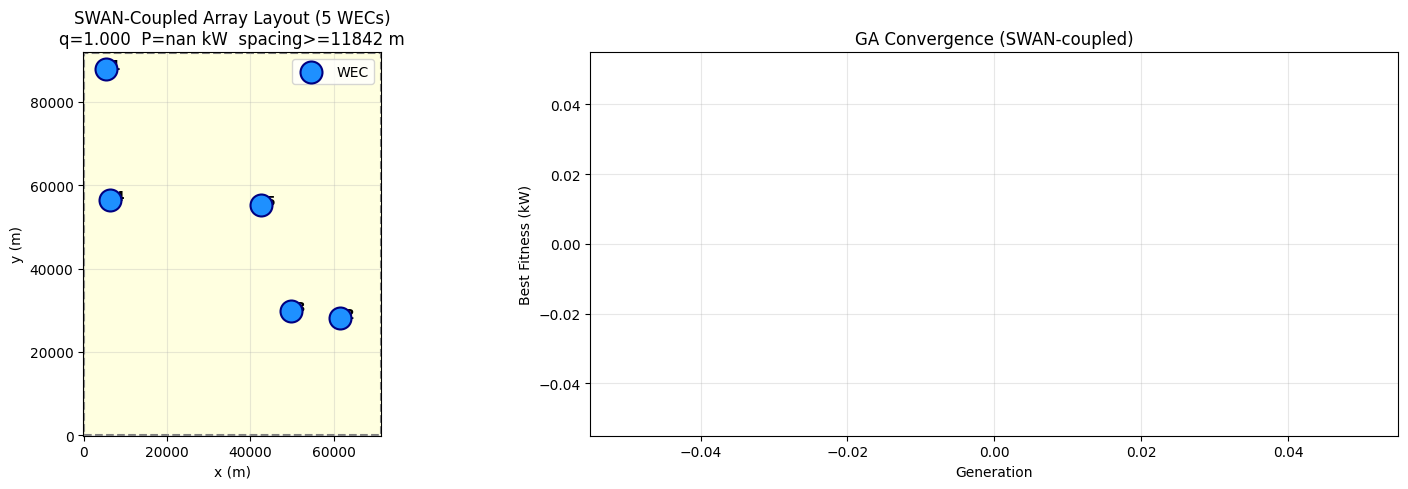

In [9]:
try:
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

    # Layout plot
    ax1.scatter(pos[:, 0], pos[:, 1], s=250, c='dodgerblue',
               edgecolors='navy', linewidths=1.5, zorder=5, label='WEC')
    for i, (x, y) in enumerate(pos):
        ax1.annotate(f' {i+1}', (x, y), fontsize=10, fontweight='bold')
    ax1.add_patch(Rectangle((0, 0), domain_m[0], domain_m[1],
                             lw=1.5, ec='grey', fc='lightyellow', ls='--'))
    ax1.set_xlim(-100, domain_m[0] + 100)
    ax1.set_ylim(-100, domain_m[1] + 100)
    ax1.set_aspect('equal')
    ax1.set_xlabel('x (m)'); ax1.set_ylabel('y (m)')
    ax1.set_title(f"SWAN-Coupled Array Layout ({n_wecs} WECs)\n"
                  f"q={q_arr:.3f}  P={total_p:.0f} kW  "
                  f"spacing>={min(dists):.0f} m")
    ax1.legend(); ax1.grid(True, alpha=.3)

    # Convergence plot
    ax2.plot(hist, color='darkblue', lw=1.2)
    ax2.set_xlabel('Generation'); ax2.set_ylabel('Best Fitness (kW)')
    ax2.set_title('GA Convergence (SWAN-coupled)')
    ax2.grid(True, alpha=.3)

    plt.tight_layout()
    plt.show()
except NameError:
    print("Results not available (SWAN was not run). Skipping plot.")

## Summary

This notebook demonstrated the complete SWAN-coupled GA array optimization:

1. **SWAN resolves** the 2-D nearshore wave field (Hs, Tp, direction, depth)
2. A **wave power interpolator** maps any (x, y) position to the local isolated WEC power
3. The **GA fitness function** combines spatially varying power with $q$-factor interactions and spacing constraints
4. The optimizer finds WEC positions that **exploit local wave energy hotspots** and **constructive interference**

Compared to the standalone GA (uniform field), the SWAN-coupled version produces layouts that are sensitive to bathymetric focusing, wave shadowing by headlands, and other nearshore effects that a uniform assumption would miss.